# Example: The INFORMS Portfolio Method on Real Data
In this example, we run the portfolio method of the INFORMS 2026 study on real daily data for the S&P 500 names that have a complete history from 2014 to 2026. We calibrate on 2014 to 2024 and trade from January 2, 2025 to September 4, 2026, the study's real-data test. We look at what the method holds, run one book day by day, and then compare the choices the study compares: the weighting rule, the picker, the hedge, and a list chosen in advance.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Compute the market state and the γ score:__ Calibrate the method on 2014 to 2024, follow the market state $\xi$ through 2025 and 2026, and rank the names by their γ score to see which ones the picker holds.
> * __Run a model-predictive book day by day:__ Run one book with the Cobb–Douglas rule and the γ picker, compare its growth rate with that of `SPY`, and read why and how often it re-planned.
> * __Compare the study's choices on one path:__ Change the weighting rule, the picker, the hedge, and the basket, and explain why one historical path cannot rank them.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

> __The MPCPortfolio module:__ The method's code is the [`MPCPortfolio` module of the course package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc/), ported from the [study's repository](https://github.com/varnerlab/INFORMS-Annual-Meeting-2026-Varnerlab). The `Include.jl` file imports it as `MPC`, so we call its functions with that name in front, for example `MPC.run_study(...)`. Some of its names are also used elsewhere in the course package, and the prefix keeps them apart.

### Data
We load the daily open and close prices and volumes of the S&P 500 names with a complete daily history from January 3, 2014 to September 4, 2026 and a sector, the `SPY` prices, and the 3-month Treasury bill rate (FRED series DTB3), with [the `MPC.load_market_data(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/). The bill rate becomes the risk-free growth rate $g_{f}$ of each day (units: 1/yr). The price files were saved at different times, so a stock split can fall between two of them; the loader puts every name on one share basis and notes each adjustment, which we do not print. We store the data in the `md::MPC.MyMarketData` variable:

In [2]:
md = let

    # load the prices, volumes, sectors, and risk-free rates (the loader's notes about split adjustments are silenced) -
    data = Logging.with_logger(Logging.NullLogger()) do
        MPC.load_market_data(_PATH_TO_MARKET_DATA; start = Date(2014, 1, 3), stop = Date(2026, 9, 4))
    end;

    # show the size of the data -
    println("$(length(data.tickers)) names in $(length(unique(data.sector))) sectors, $(length(data.dates)) trading days from $(data.dates[1]) to $(data.dates[end])");

    # checks -
    @assert all(isfinite, data.close) && all(data.close .> 0) "every close should be finite and positive"

    # return -
    data
end;

373 names in 11 sectors, 3187 trading days from 2014-01-03 to 2026-09-04


### Constants
Next, let's set the constants. The study keeps every setting in one file; we read it with [the `MPC.load_study(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/) and turn the hedge off for the first runs with `MPC.with_settings(...)`. See the comments next to the constants for definitions, units, and permissible values:

In [3]:
n_tickers = 373; # names in the universe: 373 is every name; a smaller number picks a sector-balanced subset that runs faster
train_start = Date(2014, 1, 3); # first day of the calibration window
train_stop = Date(2024, 12, 31); # last day of the calibration window
random_seed = 5660; # seed of the random picker and the forecast paths
number_of_seeds = 10; # number of random-picker books in Task 3
settings = MPC.with_settings(MPC.load_study(MPC.default_study_path()).settings; hedge = false); # the study's settings, hedge off

Let's look at the settings that matter most in this example. The run window, the picker, the limits, the triggers, and the costs are the study's:

In [4]:
let

    # the settings we refer to in this example: name, value, units -
    df = DataFrame(
        setting = ["run window", "starting wealth W₀", "names per sector N", "re-pick interval", "horizon T", "band half-width z",
            "drawdown limit", "cap per name", "cap per sector", "turnover budget", "half spread", "impact coefficient", "CES elasticity η"],
        value = ["$(settings.start) to $(settings.stop)", string(settings.W0), string(settings.N_per_sector), string(settings.repick_interval),
            string(settings.T), string(settings.z), string(settings.D_max), string(settings.w_max), string(settings.s_max),
            string(settings.turnover_frac), string(settings.half_spread_bps), string(settings.impact_kappa), string(settings.ces_eta)],
        units = ["dates", "USD", "names", "trading days", "trading days", "standard deviations", "fraction of peak wealth",
            "fraction of wealth", "fraction of wealth", "fraction of wealth", "basis points", "dimensionless", "dimensionless"]
    );

    # show the table -
    pretty_table(df; column_labels = ["setting", "value", "units"], alignment = :l,
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 -------------------- -------------------------- -------------------------
  setting              value                      units                   
 -------------------- -------------------------- -------------------------
  run window           2025-01-02 to 2026-09-04   dates
  starting wealth W₀   100000.0                   USD
  names per sector N   3                          names
  re-pick interval     21                         trading days
  horizon T            21                         trading days
  band half-width z    1.96                       standard deviations
  drawdown limit       0.08                       fraction of peak wealth
  cap per name         0.1                        fraction of wealth
  cap per sector       1.0                        fraction of wealth
  turnover budget      0.1                        fraction of wealth
  half spread          5.0                        basis points
  impact coefficient   0.001                      dimensionless
  CES

Finally, let's pick the universe and calibrate the method on 2014 to 2024. [The `MPC.select_universe(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/) returns every name when `n_tickers` is 373, and otherwise a subset with at least one name per sector. [The `MPC.calibrate(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/) fits the single index model $g_{i}=\alpha_{i}+\beta_{i}\,g_{M}+\epsilon_{i}$ of every name on the calibration window, the mean and volatility of the market growth rate, and how much to shrink the residual covariance. We store the universe in `universe::MPC.MyMarketData` and the calibration in `calibration::MPC.MyCalibration`:

In [5]:
universe, calibration = let

    # the names, and their market data -
    names = MPC.select_universe(md, n_tickers); # all names when n_tickers covers the universe
    u = MPC.subset_universe(md, names); # the same dates, SPY prices and risk-free rates

    # calibrate on 2014 to 2024: the single index model of every name, the market moments, the residual shrinkage -
    c = MPC.calibrate(u; train_start = train_start, train_stop = train_stop, window = settings.omega_window);
    println("$(length(u.tickers)) names; market growth rate on the calibration window: mean $(round(c.m_m; digits = 3)), volatility $(round(c.σ_m; digits = 3)) (1/yr)");

    # checks -
    @assert length(c.base_sim) == length(u.tickers) "one single index model per name"

    # return -
    (u, c)
end;

373 names; market growth rate on the calibration window: mean 0.106, volatility 2.741 (1/yr)


___

## Task 1: What to Hold
In this task, we compute what the method knows each day and see which names it picks. [The `MPC.build_context(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/) computes, for every day of the run, from data dated up to that day only:
* __Market state:__ $\xi_{t}=-G\left(\bar{S}^{(21)}_{t}/\bar{S}^{(63)}_{t}-1\right)$, where $\bar{S}^{(21)}_{t}$ and $\bar{S}^{(63)}_{t}$ are the 21-day and 63-day exponential moving averages of the `SPY` close and $G$ scales the ratio so that $|\xi_{t}|\leq 1$ on 99% of the calibration days. A falling market has $\xi_{t}>0$; a rising market has $\xi_{t}<0$.
* __Online single index model:__ $\hat{\alpha}_{i,t}$ and $\hat{\beta}_{i,t}$, updated every day by exponentially weighted least squares with a 63-day half-life, starting from the calibration.
* __γ score:__ $\gamma_{i,t}=\tanh\left(\left(\hat{\alpha}_{i,t}+\hat{\beta}_{i,t}\,\tilde{g}_{M,t}\right)/\max(|\hat{\beta}_{i,t}|,0.1)^{\xi_{t}}\right)$, where $\tilde{g}_{M,t}$ is a 252-day moving average of the market growth rate. When the market falls ($\xi_{t}>0$), a large $|\hat{\beta}_{i,t}|$ shrinks the score; when it rises ($\xi_{t}<0$), it raises it.

We store the result in the `context::MPC.MyStudyContext` variable:

In [6]:
context = let

    # every day's market state, online single index model, γ scores, and hedge pool, from data up to that day -
    ctx = MPC.build_context(universe, calibration, settings);

    # checks -
    @assert size(ctx.γ) == (length(ctx.rows), length(universe.tickers)) "one γ per run day and name"
    @assert all(-1 .<= ctx.γ .<= 1) "γ is a tanh, between -1 and 1"

    # return -
    ctx
end;

`Unhide` the code block below to see how we plotted the `SPY` close and the market state $\xi_{t}$ over the run.

> __What do we see?__ The market state stays negative, between about −0.25 and −0.75, while `SPY` rises. It turns positive only when `SPY` falls: in the spring 2025 sell-off it peaks near 0.9, and in the smaller dip of March 2026 near 0.4. Because it compares moving averages, it turns a few weeks after the market does.

How does the market state follow the market?

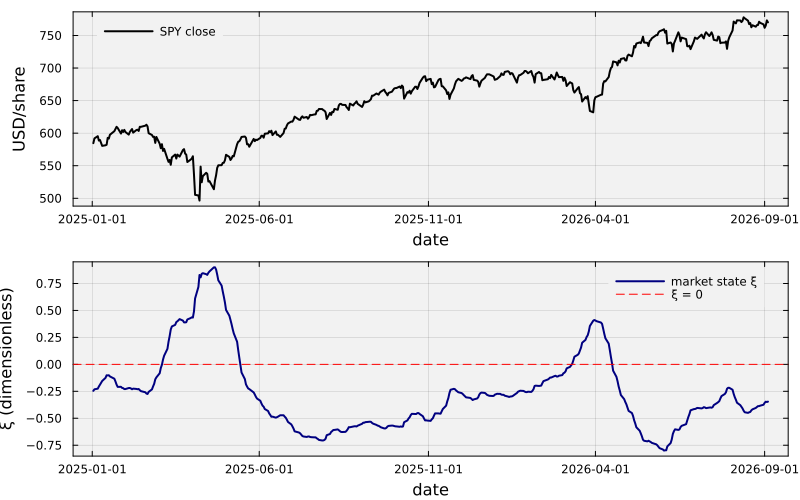

In [7]:
let

    # initialize: the run days, the SPY closes, and the market state -
    days = universe.dates[context.rows]; # run days
    spy = universe.spy_close[context.rows]; # SPY close (USD/share)
    ξ = context.ξ[context.rows]; # market state (dimensionless)

    # plot: SPY on top, ξ below -
    p1 = plot(days, spy, lw = 2, c = :black, label = "SPY close", ylabel = "USD/share",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent);
    p2 = plot(days, ξ, lw = 2, c = :navy, label = "market state ξ", ylabel = "ξ (dimensionless)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent);
    hline!(p2, [0.0], c = :red, ls = :dash, lw = 1, label = "ξ = 0");
    plot(p1, p2, layout = (2, 1), size = (800, 500), xlabel = "date")
end

Let's rank the names by γ on the first day of the run, January 2, 2025. The table shows the ten highest scores with each name's sector, $\hat{\alpha}_{i}$ (units: 1/yr), and $\hat{\beta}_{i}$ from the online single index model:

In [8]:
let

    # initialize: the first run day, its γ scores, and the online single index model -
    k = 1; # first row of the run
    t = context.rows[k]; # row of the market data
    γ = context.γ[k, :]; # γ score of every name (dimensionless)
    order = sortperm(γ; rev = true); # names from the highest γ down

    # the ten highest scores -
    top = order[1:10];
    df = DataFrame(ticker = universe.tickers[top], sector = universe.sector[top], α = context.sim.α[k, top],
        β = context.sim.β[k, top], γ = γ[top]);
    println("$(universe.dates[t]): ξ = $(round(context.ξ[t]; digits = 3)), smoothed market growth g̃ = $(round(context.g̃[t]; digits = 3)) (1/yr)");
    pretty_table(df; column_labels = ["ticker", "sector", "α̂ (1/yr)", "β̂", "γ"], alignment = [:l, :l, :r, :r, :r],
        formatters = [fmt__printf("%.3f", [3, 4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    println("names with γ > 0: $(count(γ .> 0)) of $(length(γ))");
end

2025-01-02: ξ = -0.246, smoothed market growth g̃ = 0.157 (1/yr)
 -------- ------------------------ ---------- ------- -------
  ticker   sector                   α̂ (1/yr)       β̂       γ 
 -------- ------------------------ ---------- ------- -------
  NVDA     Information Technology      0.479   1.707   0.692
  AVGO     Information Technology      0.209   1.400   0.435
  AMD      Information Technology      0.146   1.635   0.425
  MPWR     Information Technology      0.116   1.650   0.401
  MU       Information Technology      0.124   1.565   0.390
  FTNT     Information Technology      0.182   1.224   0.374
  LRCX     Information Technology      0.091   1.615   0.370
  KLAC     Information Technology      0.105   1.493   0.358
  AMAT     Information Technology      0.080   1.588   0.353
  NOW      Information Technology      0.113   1.380   0.342
 -------- ------------------------ ---------- ------- -------
names with γ > 0: 354 of 373


> __What do we see?__ On the first day of the run the market state was negative ($\xi=-0.246$), so a large $\hat{\beta}$ raised the score: the ten highest scores all belong to information technology names, with $\hat{\beta}$ between 1.2 and 1.7. Most names had a positive score, 354 of 373, so the ranking matters more than the sign.
___

## Task 2: One Book, Day by Day
In this task, we run one book on the real 2025 and 2026 data with [the `MPC.run_study(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-trading/). It starts with $W_{0}$ in cash, and on each trading day:
* __Picks:__ every 21 trading days (and when the value leaves the forecast band), the γ picker keeps the $N=3$ names with the highest γ in each sector.
* __Decides:__ after the close, it re-plans if 21 trading days have passed since the last plan, if its value has left the band of a geometric Brownian motion forecast of its holdings, or if its value is 8% below its peak. A re-plan solves the maximum-utility problem with the Cobb–Douglas rule under the limits (10% per name, the volatility cap, the sector cap, and the turnover budget).
* __Trades:__ the orders fill at the next open, in fractional shares, and pay half the bid–ask spread plus a market-impact cost.

We store the result in the `book::MPC.MyStudyResult` variable:

In [9]:
book = let

    # one run: Cobb–Douglas weights, the γ picker, hedge off -
    run = build(MPC.MyStudyRun, (settings = settings, allocator = "CD", screen = :gamma, seed = random_seed));
    result = MPC.run_study(context, run);

    # checks -
    @assert all(isfinite, result.equity) && all(result.equity .> 0) "wealth should stay finite and positive"
    @assert result.dates[1] == settings.start && result.dates[end] == settings.stop "the run should cover the run window"

    # return -
    result
end;

Let's look at the basket the picker chose on the first day, by sector:

In [10]:
let

    # the first pick: the basket, by sector -
    basket = book.repicks.basket[1]; # tickers in the first basket
    sector = [universe.sector[findfirst(==(t), universe.tickers)] for t in basket]; # sector of each name
    df = combine(groupby(DataFrame(sector = sector, ticker = basket), :sector; sort = true), :ticker => (x -> join(x, ", ")) => :names);

    # show the basket -
    pretty_table(df; column_labels = ["sector", "names picked"], alignment = :l,
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    println("$(length(basket)) names on $(book.repicks.date[1]); $(nrow(book.repicks)) picks over the run, $(count(book.repicks.changed)) of them changed the basket");
end

 ------------------------ -----------------
  sector                   names picked    
 ------------------------ -----------------
  Communication Services   GOOG, LYV, NFLX
  Consumer Discretionary   AMZN, AZO, DPZ
  Consumer Staples         COST, STZ, TGT
  Energy                   FANG, MPC, WMB
  Financials               AMP, MCO, MSCI
  Health Care              BSX, ISRG, LLY
  Industrials              CTAS, ODFL, PWR
  Information Technology   AMD, AVGO, NVDA
  Materials                MLM, PKG, VMC
  Real Estate              DLR, EQIX, IRM
  Utilities                NEE, NRG, PEG
 ------------------------ -----------------
33 names on 2025-01-02; 25 picks over the run, 25 of them changed the basket


Now let's compare the book with `SPY`. We measure both by their growth rate, $g=\ln\left(W_{\text{end}}/W_{\text{start}}\right)/\left((N-1)\,\Delta t\right)$ (units: 1/yr), where $N$ is the number of trading days and $\Delta t=1/252$, with [the `MPC.growth_scorecard(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-trading/), and by the ending wealth over the starting wealth and the largest drawdown:

In [11]:
let

    # initialize: the market data rows of the run, and the SPY closes over them -
    rows = MPC.index_of(universe, book.dates[1]):MPC.index_of(universe, book.dates[end]); # run rows
    spy = universe.spy_close[rows]; # SPY close (USD/share)
    g_f = universe.g_f[rows]; # risk-free growth rate (1/yr)

    # score the book and SPY with the same function -
    b = MPC.growth_scorecard(book.equity, spy, g_f);
    s = MPC.growth_scorecard(spy, spy, g_f);
    df = DataFrame(series = ["book (CD, γ picker)", "SPY"], g = [b.realized_growth, s.realized_growth],
        ratio = [book.equity[end] / settings.W0, spy[end] / spy[1]], drawdown = [b.max_drawdown, s.max_drawdown]);

    # show the table -
    pretty_table(df; column_labels = ["series", "growth rate g (1/yr)", "ending ÷ starting wealth", "largest drawdown"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 --------------------- ---------------------- -------------------------- ------------------
  series                growth rate g (1/yr)   ending ÷ starting wealth   largest drawdown 
 --------------------- ---------------------- -------------------------- ------------------
  book (CD, γ picker)                  0.120                      1.222              0.149
  SPY                                  0.166                      1.317              0.190
 --------------------- ---------------------- -------------------------- ------------------


`Unhide` the code block below to see how we plotted the book's wealth and the same starting wealth held in `SPY`, with the days the book re-planned.

> __What do we see?__ The book fell with `SPY` in the spring 2025 sell-off, to about 89 thousand USD, but recovered more slowly: from May to October 2025 it stayed below 100 thousand while `SPY` rose past 115. It caught up late in 2025 and ended at 122 thousand, against 132 thousand for `SPY`. The red points show a re-plan about once a month.

How did the book's wealth compare with `SPY`?

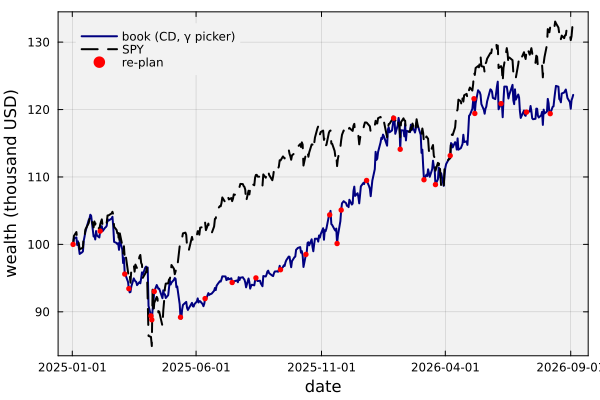

In [12]:
let

    # initialize: the run rows, SPY scaled to the starting wealth, and the decision days -
    rows = MPC.index_of(universe, book.dates[1]):MPC.index_of(universe, book.dates[end]); # run rows
    spy = settings.W0 .* universe.spy_close[rows] ./ universe.spy_close[rows[1]]; # SPY wealth (USD)
    decided = [findfirst(==(d), book.dates) for d in book.decisions.date]; # rows of the decision days

    # plot: the book and SPY, with the decision days marked -
    plot(book.dates, book.equity ./ 1000, lw = 2, c = :navy, label = "book (CD, γ picker)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legend = :topleft);
    plot!(book.dates, spy ./ 1000, lw = 2, c = :black, ls = :dash, label = "SPY");
    scatter!(book.dates[decided], book.equity[decided] ./ 1000, c = :red, ms = 3, msw = 0, label = "re-plan");
    xlabel!("date"); ylabel!("wealth (thousand USD)")
end

Why did the book re-plan? Each decision records its reason and the solver's status:

In [13]:
let

    # count the decisions by reason, and by solver status -
    reasons = combine(groupby(book.decisions, :reason; sort = true), nrow => :count);
    statuses = combine(groupby(book.decisions, :status; sort = true), nrow => :count);

    # show the counts -
    pretty_table(reasons; column_labels = ["reason", "decisions"], alignment = [:l, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    pretty_table(statuses; column_labels = ["solver status", "decisions"], alignment = [:l, :r],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    println("names held per decision: median $(median(book.decisions.n_names)), invested fraction: median $(round(median(book.decisions.invested_frac); digits = 3))");

    # checks: a failed solve keeps the book, and every decision has an accepted or failed status -
    @assert issubset(Set(book.decisions.status), Set([:optimal, :fallback_minvar, :long_only_fallback, :infeasible, :solver_failed])) "unexpected solver status"
end

 ----------------- -----------
  reason            decisions 
 ----------------- -----------
  band_exit                 8
  basket_change             1
  drawdown                  3
  horizon_elapsed          14
  initial                   1
 ----------------- -----------
 --------------- -----------
  solver status   decisions 
 --------------- -----------
  optimal                27
 --------------- -----------
names held per decision: median 33.0, invested fraction: median 1.0


> __What do we see?__ The book re-planned 27 times. Fourteen re-plans came at the 21-day horizon, eight when its value left the forecast band, and three at the 8% drawdown limit, so 11 of the 27 came early. Every allocation problem was solved (`optimal`), and the book held about 33 names and stayed fully invested.
___

## Task 3: The Study's Comparisons on One Path
In this task, we change one choice at a time and run the book again on the same real data. We keep the rest of the settings, and we score every book with the growth rate and the ending wealth over the starting wealth. The comparisons are the study's:
* __Weighting rule:__ the seven rules on the γ basket: Cobb–Douglas (`CD`), CES on share counts (`CES`, η = 0.5), CES on weights (`CESw`), Stone–Geary (`SG`), minimum variance (`MinVar`), the tangency portfolio (`Tangent`), and a 130/30 long–short Cobb–Douglas book (`LS`).
* __Picker:__ the γ picker against a random picker with the same number of names per sector, over several seeds.
* __Hedge:__ the γ book with the β-cap hedge on, which caps the book's β more tightly as $\xi_{t}$ rises and can hold up to five names with $\beta\leq 0$.
* __A list chosen in advance:__ the 13 names of L8b, chosen without 2025 data.

First, we write a small function that runs one book and scores it, so every comparison uses the same steps:

In [14]:
"""
    score(ctx, s, allocator, screen, seed) -> NamedTuple

Run one book with `MPC.run_study` on the context `ctx` with settings `s` and score it: the growth rate `g` (1/yr),
the ending wealth over `s.W0`, the largest drawdown (fraction), and the number of decisions.
"""
function score(ctx, s, allocator::String, screen::Symbol, seed::Int)

    # run the book -
    result = MPC.run_study(ctx, build(MPC.MyStudyRun, (settings = s, allocator = allocator, screen = screen, seed = seed)));

    # score it on the same rows as SPY -
    rows = MPC.index_of(ctx.md, result.dates[1]):MPC.index_of(ctx.md, result.dates[end]); # run rows
    sc = MPC.growth_scorecard(result.equity, ctx.md.spy_close[rows], ctx.md.g_f[rows]);

    # return -
    return (g = sc.realized_growth, ratio = result.equity[end] / s.W0, drawdown = sc.max_drawdown,
        decisions = nrow(result.decisions));
end;

Let's run the seven weighting rules on the γ basket:

In [15]:
rules = let

    # every weighting rule of the study, on the γ picker, hedge off -
    allocators = ["CD", "CES", "CESw", "SG", "MinVar", "Tangent", "LS"]; # the study's rules
    rows = [merge((rule = a,), score(context, settings, a, :gamma, random_seed)) for a in allocators];
    df = DataFrame(rows);

    # show the table -
    pretty_table(df; column_labels = ["rule", "growth rate g (1/yr)", "ending ÷ starting wealth", "largest drawdown", "decisions"],
        alignment = [:l, :r, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # return -
    df
end;

 --------- ---------------------- -------------------------- ------------------ -----------
  rule      growth rate g (1/yr)   ending ÷ starting wealth   largest drawdown   decisions 
 --------- ---------------------- -------------------------- ------------------ -----------
  CD                       0.120                      1.222              0.149          27
  CES                      0.119                      1.219              0.160          29
  CESw                     0.125                      1.232              0.173          27
  SG                       0.127                      1.234              0.173          27
  MinVar                   0.048                      1.082              0.104          31
  Tangent                  0.126                      1.233              0.150          35
  LS                       0.096                      1.173              0.150          29
 --------- ---------------------- -------------------------- ------------------ -------

> __What do we see?__ Five of the seven rules ended close together, with growth rates from 0.119 to 0.127 (1/yr), because they weighted the same basket. Minimum variance grew much less (0.048) but had the smallest drawdown (0.104), and the 130/30 book grew less (0.096). The next comparison keeps the rule and changes the basket.

Next, the picker. We run the Cobb–Douglas book with the random picker for `number_of_seeds` seeds and compare the spread of their growth rates with the γ book:

In [16]:
let

    # the γ book, and the random-picker books, one per seed -
    γ_book = score(context, settings, "CD", :gamma, random_seed);
    random_books = [score(context, settings, "CD", :random, random_seed + k) for k in 0:(number_of_seeds - 1)];
    g_random = [b.g for b in random_books]; # growth rates of the random books (1/yr)

    # summarize -
    println("γ picker: g = $(round(γ_book.g; digits = 3)) (1/yr)");
    println("random picker, $(number_of_seeds) seeds: min $(round(minimum(g_random); digits = 3)), median $(round(median(g_random); digits = 3)), max $(round(maximum(g_random); digits = 3)) (1/yr)");
    println("random books with a higher growth rate than the γ book: $(count(g_random .> γ_book.g)) of $(number_of_seeds)");
end

γ picker: g = 0.12 (1/yr)
random picker, 10 seeds: min -0.013, median 0.129, max 0.212 (1/yr)
random books with a higher growth rate than the γ book: 5 of 10


> __What do we see?__ The random books spread widely, from −0.013 to 0.212 (1/yr), with a median of 0.129, close to the γ book's 0.120; five of the ten grew faster. Changing the names moved the growth rate far more than changing the weighting rule did. On this one path, the γ basket ranked in the middle of the random ones.

Finally, the hedge and the list chosen in advance. The hedge changes what the method computes each day (the β cap and the hedge pool), so it needs its own context:

In [17]:
let

    # the hedge on: its own context, then the Cobb–Douglas γ book -
    settings_hedged = MPC.with_settings(settings; hedge = true); # the β-cap hedge on
    context_hedged = MPC.build_context(universe, calibration, settings_hedged);
    hedged = score(context_hedged, settings_hedged, "CD", :gamma, random_seed);

    # the list chosen in advance: the 13 names of L8b (the :fixed picker) -
    fixed_ok = issubset(settings.fixed_tickers, universe.tickers); # every listed name must be in the universe
    fixed = fixed_ok ? score(context, settings, "CD", :fixed, random_seed) : missing;

    # compare with the unhedged γ book -
    γ_book = score(context, settings, "CD", :gamma, random_seed);
    df = DataFrame(book = ["CD, γ picker", "CD, γ picker, hedge on", "CD, the 13 names of L8b"],
        g = [γ_book.g, hedged.g, fixed_ok ? fixed.g : missing], ratio = [γ_book.ratio, hedged.ratio, fixed_ok ? fixed.ratio : missing],
        drawdown = [γ_book.drawdown, hedged.drawdown, fixed_ok ? fixed.drawdown : missing]);
    pretty_table(df; column_labels = ["book", "growth rate g (1/yr)", "ending ÷ starting wealth", "largest drawdown"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    if !fixed_ok
        println("The L8b list is not inside this universe; set n_tickers = 373 to run it.");
    end
end

 ------------------------- ---------------------- -------------------------- ------------------
  book                      growth rate g (1/yr)   ending ÷ starting wealth   largest drawdown 
 ------------------------- ---------------------- -------------------------- ------------------
  CD, γ picker                             0.120                      1.222              0.149
  CD, γ picker, hedge on                   0.114                      1.209              0.157
  CD, the 13 names of L8b                  0.262                      1.546              0.192
 ------------------------- ---------------------- -------------------------- ------------------


> __What do we see?__ On this path the hedge lowered the growth rate a little (0.114 against 0.120) and did not reduce the largest drawdown (0.157 against 0.149). The 13 names of L8b, chosen without 2025 data and six of them technology stocks, grew fastest (0.262) with the largest drawdown (0.192). One path rewards whatever happened to work on it.

Your numbers will differ if you change the constants: try a smaller `n_tickers`, another `random_seed`, or `MPC.with_settings(settings; N_per_sector = 2)`.
___

## Summary
In this example, we ran the portfolio method of the INFORMS 2026 study on real data for 2025 and 2026, after calibrating it on 2014 to 2024.

> __Key Takeaways:__
>
> * __The market state and the γ score decide what to hold:__ We calibrated the single index model on 2014 to 2024 and updated it every day. The market state turned positive only in the two sell-offs, and while it was negative the γ score favored names with a large β, so the picker held the highest-scoring names of each sector.
> * __The book re-plans on a schedule and when the market surprises it:__ We ran one Cobb–Douglas book day by day. It re-planned at the 21-day horizon, and earlier when its value left the forecast band or fell 8% from its peak. On the real 2025 and 2026 data it grew more slowly than `SPY`, with a smaller drawdown.
> * __One path cannot rank the choices:__ We changed the weighting rule, the picker, the hedge, and the basket. The weighting rules ended close together while different baskets ended far apart, and a single historical path cannot tell a good choice from a lucky one.

A backtest is one historical path. To judge the method, we need many markets that could have happened, which is what a synthetic market generator provides.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___